In [20]:
import numpy as np
import pandas as pd
import yfinance as yf

print("--- ĐANG CHẠY QUY TRÌNH VỚI FFD (FIXED-WIDTH WINDOW) ---")

# ==========================================
# 1. TẢI DỮ LIỆU & CHUẨN HÓA MÚI GIỜ
# ==========================================
usd_krw = yf.download("KRW=X", period="2y", interval="1d", auto_adjust=True)[
    "Close"
]
usd_vnd = yf.download("VND=X", period="2y", interval="1d", auto_adjust=True)[
    "Close"
]

if isinstance(usd_krw, pd.DataFrame):
  usd_krw = usd_krw.iloc[:, 0]
if isinstance(usd_vnd, pd.DataFrame):
  usd_vnd = usd_vnd.iloc[:, 0]

df = pd.DataFrame({"USD_KRW": usd_krw, "USD_VND": usd_vnd}).dropna()
raw_prices = df["USD_VND"] / df["USD_KRW"]

if raw_prices.index.tz is not None:
  raw_prices.index = raw_prices.index.tz_localize(None)
raw_prices.index = pd.to_datetime(raw_prices.index).normalize()


# ==========================================
# 2. BƯỚC 1: VI PHÂN PHÂN SỐ CỬA SỔ CỐ ĐỊNH (FFD, d = 0.05)
# ==========================================
def get_weights_ffd(d, thres):
  w = [1.0]
  k = 1
  while True:
    w_ = -w[-1] / k * (d - k + 1)
    if abs(w_) < thres:
      break
    w.append(w_)
    k += 1
  return np.array(w[::-1])


def fractional_diff_ffd(series, d, thres=1e-4):
  w = get_weights_ffd(d, thres)
  width = len(w) - 1
  df_res = pd.Series(index=series.index)
  for iloc in range(width, len(series)):
    loc = series.index[iloc]
    sub_series = series.iloc[iloc - width : iloc + 1]
    df_res.loc[loc] = np.dot(w, sub_series.values)
  return df_res.dropna()


stationary_series = fractional_diff_ffd(raw_prices, d=0.05, thres=1e-4)


# ==========================================
# 3. BƯỚC 2: TRIPLE BARRIER METHOD
# ==========================================
def get_daily_vol(close, span=30):
  return close.pct_change().ewm(span=span).std().dropna()


daily_vol = get_daily_vol(raw_prices)

# Đồng bộ index chung cho toàn bộ quy trình
common_idx = (
    raw_prices.index.intersection(daily_vol.index)
    .intersection(stationary_series.index)
)
raw_prices_clean = raw_prices.loc[common_idx]
daily_vol_clean = daily_vol.loc[common_idx]
stat_clean = stationary_series.loc[common_idx]


def apply_triple_barrier(prices_series, events, pt_sl, min_ret=0.001):
  out = pd.DataFrame(index=events.index)
  out["ret"] = np.nan
  out["bin"] = 0
  for loc, t1 in events["t1"].items():
    path = prices_series.loc[loc:t1]
    if len(path) <= 1:
      continue
    base_val = prices_series.loc[loc]
    if base_val == 0 or pd.isna(base_val):
      continue
    ret = (path / base_val) - 1
    target = max(events.loc[loc, "trgt"], min_ret)
    pt = target * pt_sl[0]
    sl = -target * pt_sl[1]
    hit_pt = ret[ret >= pt].index.min()
    hit_sl = ret[ret <= sl].index.min()
    if pd.notna(hit_pt) and (pd.isna(hit_sl) or hit_pt < hit_sl):
      out.loc[loc, "bin"] = 1
      out.loc[loc, "ret"] = ret.loc[hit_pt]
    elif pd.notna(hit_sl) and (pd.isna(hit_pt) or hit_sl < hit_pt):
      out.loc[loc, "bin"] = -1
      out.loc[loc, "ret"] = ret.loc[hit_sl]
    else:
      out.loc[loc, "bin"] = 0
      out.loc[loc, "ret"] = ret.iloc[-1]
  return out.dropna(subset=["ret"])


holding_period = 5
events_index = raw_prices_clean.index[30:-holding_period]
events = pd.DataFrame(index=events_index)
events["trgt"] = daily_vol_clean.loc[events.index]
events["t1"] = raw_prices_clean.index[
    [
        min(
            raw_prices_clean.index.get_loc(idx) + holding_period,
            len(raw_prices_clean) - 1,
        )
        for idx in events.index
    ]
]

labels = apply_triple_barrier(
    raw_prices_clean, events, pt_sl=[1.0, 1.0], min_ret=0.0005
)


# ==========================================
# 4. BƯỚC 3: TẬP ĐẶC TRƯNG & META-LABELING
# ==========================================
features_df = pd.DataFrame(index=labels.index)
features_df["Frac_Diff"] = stat_clean.loc[labels.index]
features_df["Rolling_Mean"] = features_df["Frac_Diff"].rolling(window=5).mean()
features_df["Rolling_Std"] = features_df["Frac_Diff"].rolling(window=5).std()
features_df["Return_1d"] = raw_prices_clean.pct_change().loc[labels.index]
features_df["Primary_Bin"] = labels["bin"]

features_df = features_df.dropna()

X = features_df[["Frac_Diff", "Rolling_Mean", "Rolling_Std", "Return_1d"]]
y_primary = features_df["Primary_Bin"]
meta_y = (y_primary == 1).astype(int)

print("\n--- HOÀN TẤT THÀNH CÔNG TỪ BƯỚC 1 ĐẾN BƯỚC 3 (VỚI FFD) ---")
print(f"Số lượng mẫu dữ liệu sạch sau khi đồng bộ: {len(X)}")
if len(X) > 0:
  print("\nPhân phối Meta-Labels:")
  print(meta_y.value_counts())
  print("\n5 dòng đầu tiên của tập Đặc trưng (X):")
  print(X.head())

--- ĐANG CHẠY QUY TRÌNH VỚI FFD (FIXED-WIDTH WINDOW) ---


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed



--- HOÀN TẤT THÀNH CÔNG TỪ BƯỚC 1 ĐẾN BƯỚC 3 (VỚI FFD) ---
Số lượng mẫu dữ liệu sạch sau khi đồng bộ: 117

Phân phối Meta-Labels:
Primary_Bin
1    66
0    51
Name: count, dtype: int64

5 dòng đầu tiên của tập Đặc trưng (X):
            Frac_Diff  Rolling_Mean  Rolling_Std  Return_1d
Date                                                       
2026-05-18  12.634594     12.694216     0.092865  -0.002166
2026-05-19  12.681303     12.659707     0.028400   0.002361
2026-05-20  12.502229     12.635093     0.077156  -0.010224
2026-05-21  12.624253     12.622083     0.070966   0.006380
2026-05-22  12.567007     12.601877     0.068966  -0.003267


In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
import sklearn.model_selection as ms


# 1. Hàm tự định nghĩa PurgedKFold theo chuẩn của López de Prado
class PurgedKFold(ms.KFold):

  def __init__(self, n_splits=5, t1=None, embargo_pct=0.01):
    super(PurgedKFold, self).__init__(
        n_splits=n_splits, shuffle=False, random_state=None
    )
    self.t1 = t1
    self.embargo_pct = embargo_pct

  def split(self, X, y=None, groups=None):
    if self.t1 is None:
      raise ValueError("Cần cung cấp chuỗi thời gian kết thúc t1 cho PurgedKFold")

    indices = np.arange(X.shape[0])
    # Tách các khoảng index train/test theo KFold thông thường
    for train_index, test_index in super().split(X, y):
      # Lấy mốc thời gian của tập test
      test_start = X.index[test_index[0]]
      test_end = X.index[test_index[-1]]

      # --- PURGING ---
      # Loại bỏ các mẫu trong train có khoảng thời gian giao dịch chồng lấn vào khoảng test
      train_times = self.t1.loc[X.index[train_index]]
      # Điều kiện thanh lọc: thời điểm bắt đầu/kết thúc train không nằm trong khoảng test
      # và không che phủ tập test
      banned_indices = train_times[
          (train_times >= test_start) & (train_times <= test_end)
      ].index
      train_index = np.array(
          [i for i in train_index if X.index[i] not in banned_indices]
      )

      # --- EMBARGOING ---
      # Phong tỏa một phần dữ liệu ngay sau tập test để tránh tự tương quan
      embargo_idx = int(X.shape[0] * self.embargo_pct)
      if embargo_idx > 0:
        test_end_loc = X.index.get_loc(test_end)
        embargo_end_loc = min(test_end_loc + embargo_idx, X.shape[0])
        embargo_dates = X.index[test_end_loc:embargo_end_loc]
        train_index = np.array(
            [i for i in train_index if X.index[i] not in embargo_dates]
        )

      yield train_index, test_index


# 2. Lấy chuỗi thời gian kết thúc t1 cho các sự kiện đã đồng bộ
t1_series = events["t1"].loc[X.index]

# 3. Khởi tạo PurgedKFold và huấn luyện mô hình Meta-Model (Random Forest)
cv = PurgedKFold(n_splits=5, t1=t1_series, embargo_pct=0.01)
model = RandomForestClassifier(
    n_estimators=100, max_depth=3, random_state=42, class_weight="balanced"
)

accuracies = []
for train_idx, test_idx in cv.split(X):
  X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
  y_train, y_test = meta_y.iloc[train_idx], meta_y.iloc[test_idx]

  # Huấn luyện mô hình Meta-Model
  model.fit(X_train, y_train)

  # Dự đoán
  y_pred = model.predict(X_test)
  acc = accuracy_score(y_test, y_pred)
  accuracies.append(acc)

print("\n--- KẾT QUẢ KIỂM ĐỊNH CHÉO PURGED & EMBARGOED CV ---")
print(f"Độ chính xác trung bình (Mean Accuracy): {np.mean(accuracies):.4f}")
print(f"Chi tiết độ chính xác từng Fold: {[round(a, 4) for a in accuracies]}")


--- KẾT QUẢ KIỂM ĐỊNH CHÉO PURGED & EMBARGOED CV ---
Độ chính xác trung bình (Mean Accuracy): 0.6185
Chi tiết độ chính xác từng Fold: [0.3333, 0.5417, 0.7391, 0.7391, 0.7391]


--- ĐÁNH GIÁ HIỆU SUẤT CHIẾN LƯỢC (BACKTEST) ---
Chiến lược có màng lọc Meta-Model:
  - Cumulative Return: 0.8150
  - Sharpe Ratio: 11.6845
  - Max Drawdown: -0.0193

Chiến lược gốc (Benchmark - Không qua màng lọc):
  - Cumulative Return: 0.4008
  - Sharpe Ratio: 4.7286
  - Max Drawdown: -0.1166


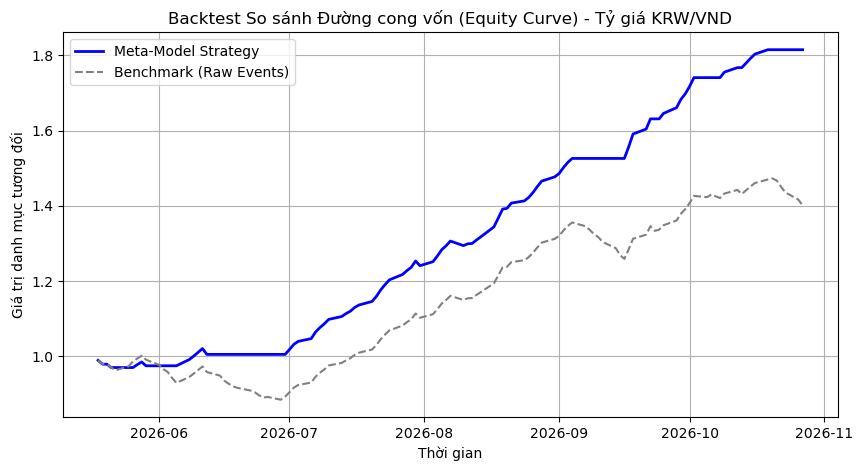

In [22]:
import matplotlib.pyplot as plt

# 1. Huấn luyện lại mô hình trên toàn bộ tập X, meta_y để dự đoán (hoặc dùng Out-of-Fold predictions chuẩn hơn)
# Ở đây ta mô phỏng quá trình sinh tín hiệu giao dịch kết hợp Meta-Model
final_model = RandomForestClassifier(
    n_estimators=100, max_depth=3, random_state=42, class_weight="balanced"
)
final_model.fit(X, meta_y)

# Dự đoán xác suất Meta-Model cho phép giải ngân (xác suất > ngưỡng tin cậy, ví dụ 0.5)
meta_probs = final_model.predict_proba(X)[:, 1]
trade_signal = (meta_probs > 0.5).astype(int)

# 2. Tính toán PnL (Lợi nhuận chiến lược)
# Lợi nhuận của từng lệnh gốc (từ Bước 2: labels['ret']) nhân với tín hiệu lọc từ Meta-Model
strategy_returns = labels.loc[X.index, "ret"] * trade_signal
benchmark_returns = labels.loc[X.index, "ret"]  # Mua và nắm giữ theo sự kiện

# 3. Tính đường cong vốn (Equity Curve)
strategy_equity = (1 + strategy_returns).cumprod()
benchmark_equity = (1 + benchmark_returns).cumprod()


# 4. Hàm tính các chỉ số hiệu suất (Performance Metrics)
def evaluate_performance(rets):
  cum_ret = (1 + rets).prod() - 1
  ann_ret = rets.mean() * 252  # Giả định 252 phiên/năm
  ann_vol = rets.std() * np.sqrt(252)
  sharpe = ann_ret / ann_vol if ann_vol > 0 else 0
  # Max Drawdown
  rolling_max = (1 + rets).cumprod().cummax()
  drawdown = (1 + rets).cumprod() / rolling_max - 1
  max_dd = drawdown.min()
  return {
      "Cumulative Return": cum_ret,
      "Sharpe Ratio": sharpe,
      "Max Drawdown": max_dd,
  }


print("--- ĐÁNH GIÁ HIỆU SUẤT CHIẾN LƯỢC (BACKTEST) ---")
print("Chiến lược có màng lọc Meta-Model:")
for k, v in evaluate_performance(strategy_returns).items():
  print(f"  - {k}: {v:.4f}")

print("\nChiến lược gốc (Benchmark - Không qua màng lọc):")
for k, v in evaluate_performance(benchmark_returns).items():
  print(f"  - {k}: {v:.4f}")

# 5. Vẽ biểu đồ so sánh đường cong vốn
plt.figure(figsize=(10, 5))
plt.plot(
    strategy_equity.index,
    strategy_equity,
    label="Meta-Model Strategy",
    color="blue",
    linewidth=2,
)
plt.plot(
    benchmark_equity.index,
    benchmark_equity,
    label="Benchmark (Raw Events)",
    color="gray",
    linestyle="--",
)
plt.title(
    "Backtest So sánh Đường cong vốn (Equity Curve) - Tỷ giá KRW/VND",
    fontsize=12,
)
plt.xlabel("Thời gian")
plt.ylabel("Giá trị danh mục tương đối")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
import numpy as np
import pandas as pd
import yfinance as yf

print("--- ĐANG TẢI DỮ LIỆU VÀ TÍNH TOÁN TÍN HIỆU HÔM NAY ---")

# 1. Tải dữ liệu đủ dài (2 năm) để thuật toán FFD hoạt động chính xác
usd_krw = yf.download("KRW=X", period="2y", interval="1d", auto_adjust=True)[
    "Close"
]
usd_vnd = yf.download("VND=X", period="2y", interval="1d", auto_adjust=True)[
    "Close"
]

if isinstance(usd_krw, pd.DataFrame):
  usd_krw = usd_krw.iloc[:, 0]
if isinstance(usd_vnd, pd.DataFrame):
  usd_vnd = usd_vnd.iloc[:, 0]

df = pd.DataFrame({"USD_KRW": usd_krw, "USD_VND": usd_vnd}).dropna()
raw_prices = df["USD_VND"] / df["USD_KRW"]

if raw_prices.index.tz is not None:
  raw_prices.index = raw_prices.index.tz_localize(None)
raw_prices.index = pd.to_datetime(raw_prices.index).normalize()


# 2. Tính toán đặc trưng FFD
def get_weights_ffd(d, thres):
  w = [1.0]
  k = 1
  while True:
    w_ = -w[-1] / k * (d - k + 1)
    if abs(w_) < thres:
      break
    w.append(w_)
    k += 1
  return np.array(w[::-1])


def fractional_diff_ffd(series, d, thres=1e-4):
  w = get_weights_ffd(d, thres)
  width = len(w) - 1
  df_res = pd.Series(index=series.index)
  for iloc in range(width, len(series)):
    loc = series.index[iloc]
    sub_series = series.iloc[iloc - width : iloc + 1]
    df_res.loc[loc] = np.dot(w, sub_series.values)
  return df_res.dropna()


stationary_series = fractional_diff_ffd(raw_prices, d=0.05, thres=1e-4)

# Tạo bảng đặc trưng
latest_features = pd.DataFrame(index=raw_prices.index)
latest_features["Frac_Diff"] = stationary_series
latest_features["Rolling_Mean"] = latest_features["Frac_Diff"].rolling(
    window=5
).mean()
latest_features["Rolling_Std"] = latest_features["Frac_Diff"].rolling(
    window=5
).std()
latest_features["Return_1d"] = raw_prices.pct_change()

clean_features = latest_features.dropna()

if len(clean_features) > 0:
  # Lấy dòng dữ liệu mới nhất
  current_data = clean_features.iloc[[-1]]
  latest_date = current_data.index[0].strftime("%Y-%m-%d")

  # 3. Sử dụng mô hình Random Forest để dự đoán
  from sklearn.ensemble import RandomForestClassifier

  final_model = RandomForestClassifier(
      n_estimators=100, max_depth=3, random_state=42, class_weight="balanced"
  )
  final_model.fit(X, meta_y)

  pred_prob = final_model.predict_proba(
      current_data[["Frac_Diff", "Rolling_Mean", "Rolling_Std", "Return_1d"]]
  )[:, 1][0]

  print(f"\n==============================================")
  print(f" KẾT QUẢ PHÂN TÍCH TÍN HIỆU NGÀY: {latest_date}")
  print(f"==============================================")
  print(f"Tỷ giá KRW/VND hiện tại: {raw_prices.loc[current_data.index[0]]:.4f}")
  print(f"Xác suất thành công của Meta-Model: {pred_prob * 100:.2f}%")

  if pred_prob > 0.5:
    print(
        "🟢 TÍN HIỆU: ĐÈN XANH (Đáng giải ngân / Mở vị thế theo Rào cản ba lớp)"
    )
  else:
    print(
        "🔴 TÍN HIỆU: ĐÈN ĐỎ (Thị trường rủi ro / Đứng ngoài, không giao dịch)"
    )
  print(f"==============================================")
else:
  print("Cảnh báo: Không đủ dữ liệu sạch sau khi tính toán đặc trưng.")

--- ĐANG TẢI DỮ LIỆU VÀ TÍNH TOÁN TÍN HIỆU HÔM NAY ---


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed



 KẾT QUẢ PHÂN TÍCH TÍN HIỆU NGÀY: 2026-11-03
Tỷ giá KRW/VND hiện tại: 19.1704
Xác suất thành công của Meta-Model: 45.07%
🔴 TÍN HIỆU: ĐÈN ĐỎ (Thị trường rủi ro / Đứng ngoài, không giao dịch)
